# Aplicação do Map-Optimize-Learn

Este notebook aplica o MOL à base Breast Cancer Wisconsin, etapa por etapa, com visualizações:

1. **Map:** a nota de cada feature e o ranking
2. **Optimize:** o formato da imagem, as features escolhidas e o que a função objetivo mede
3. **Learn:** a CNN e o desempenho no teste
4. Comparação com os métodos tradicionais
5. Testes de controle
6. MOL v2, a versão corrigida
7. Uso dos modelos salvos

As seções 1 a 3 e 6 rodam o código do pacote `mol` aqui mesmo. As seções 4 e 5 leem os resultados dos
experimentos completos, que levam de 25 a 45 minutos cada e ficam em `results/`.

In [1]:
import os
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import joblib
import keras
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display
from scipy.stats import spearmanr
from sklearn.metrics import confusion_matrix

from mol.algorithm import MAP_STRATEGIES, MapOptimizeLearn
from mol.cnn import MOLCNNClassifier
from mol.data import RAIZ, prepare_data_pipeline
from mol.utils import calculate_metrics
from mol.v2 import MOLv2Classifier

%matplotlib inline
tf.get_logger().setLevel("ERROR")
sns.set_theme(style="whitegrid")
AZUL, LARANJA = "#4C9BE8", "#F2994A"
RESULTADOS = RAIZ / "results"

In [2]:
dados = prepare_data_pipeline()
X_treino, y_treino = dados["X_train"], dados["y_train"]
X_teste, y_teste = dados["X_test"], dados["y_test"]
nomes = np.array(dados["feature_names"])

Dataset: 569 amostras, 30 features (357 benignos, 212 malignos)
Treino: 455 (170 malignos) | Teste: 114 (42 malignos)


## 1. Map: a nota de cada feature

O Map dá a cada feature uma nota de quanto ela separa benignos de malignos e ordena as features por essa
nota. A ordem define a posição de cada feature na imagem: a primeira do ranking vira o pixel 1.

O artigo testa vários critérios. Abaixo, a nota de cada feature em cada um, calculada no treino.

In [3]:
notas = {}
for criterio in MAP_STRATEGIES:
    # o otimizador não importa aqui: só a etapa Map é usada
    m = MapOptimizeLearn(map_strategy=criterio, optimizer="random", max_evaluations=1).fit(X_treino, y_treino)
    notas[criterio] = m.feature_scores_
notas = pd.DataFrame(notas, index=nomes)
notas.sort_values("euclidean", ascending=False).head(8).round(3)

,euclidean,anova,pearson,fisher,gain_ratio,mutual_info,random_forest
concave points_worst,1.625,733.725,0.786,1.620,0.189,0.433,0.126
perimeter_worst,1.618,717.246,0.783,1.583,0.207,0.455,0.084
radius_worst,1.607,692.861,0.778,1.529,0.197,0.461,0.093
concave points_mean,1.604,684.527,0.776,1.511,0.190,0.446,0.081
perimeter_mean,1.530,548.413,0.740,1.211,0.169,0.409,0.077
area_worst,1.513,522.189,0.732,1.153,0.198,0.453,0.151
radius_mean,1.505,511.275,0.728,1.129,0.166,0.373,0.062
area_mean,1.455,444.858,0.704,0.982,0.165,0.375,0.046


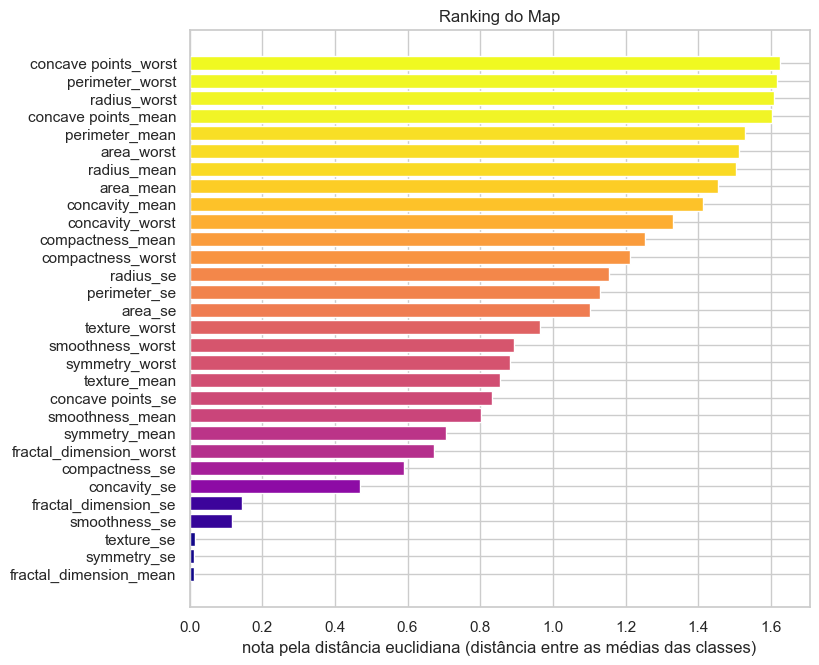

In [4]:
ordem = notas["euclidean"].sort_values()
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(ordem.index, ordem.values, color=plt.cm.plasma(ordem.values / ordem.max()))
ax.set_xlabel("nota pela distância euclidiana (distância entre as médias das classes)")
ax.set_title("Ranking do Map")
plt.show()

### Os critérios concordam entre si?

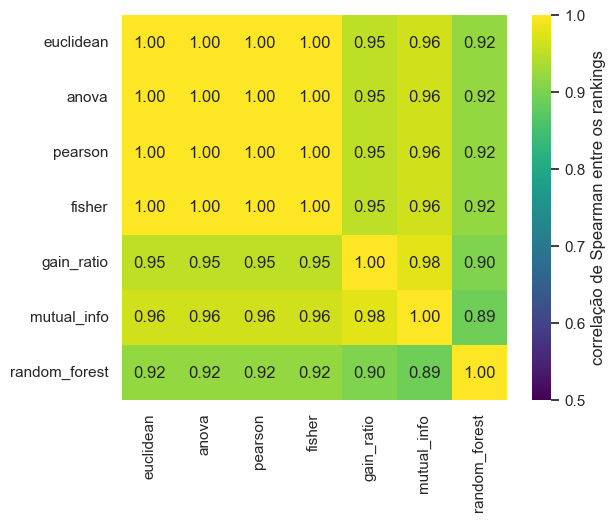

In [5]:
rho = pd.DataFrame(spearmanr(notas.values).statistic, index=notas.columns, columns=notas.columns)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="viridis", vmin=0.5, vmax=1, square=True,
            cbar_kws={"label": "correlação de Spearman entre os rankings"}, ax=ax)
plt.show()

Distância euclidiana, ANOVA, Pearson e Fisher produzem exatamente o mesmo ranking (correlação 1,00). Com
duas classes e dados padronizados, os quatro são funções crescentes uns dos outros. Os demais critérios
dão rankings parecidos, mas não iguais.

## 2. Optimize: formato e seleção de features

O Optimize procura um vetor com a altura, a largura e um bit por feature (entra ou não entra na imagem).
A busca é feita por um algoritmo de enxame, que minimiza a função objetivo do artigo (Eq. 1): a diferença
quadrática média entre a imagem de um paciente e a do paciente seguinte.

O artigo não diz como as amostras são ordenadas nessa comparação. Aqui elas são ordenadas por classe.

In [6]:
mols = {nome: MapOptimizeLearn(map_strategy="euclidean", optimizer=nome).fit(X_treino, y_treino)
        for nome in ["pso", "epso", "abc"]}

pd.DataFrame([{"otimizador": nome.upper(),
               "formato": f"{m.image_shape_[0]}×{m.image_shape_[1]}",
               "features": int(m.selected_mask_.sum()),
               "f (Eq. 1)": round(m.objective_value_, 3),
               "features escolhidas": ", ".join(nomes[m.selected_features_][:4])
                                      + (" ..." if m.selected_mask_.sum() > 4 else "")}
              for nome, m in mols.items()]).set_index("otimizador")

,formato,features,f (Eq. 1),features escolhidas
otimizador,,,,
PSO,1×2,2,0.797,"concave points_worst, radius_worst"
EPSO,1×2,2,0.778,"perimeter_worst, radius_worst"
ABC,16×1,16,1.307,"concave points_worst, radius_worst, perimeter_..."


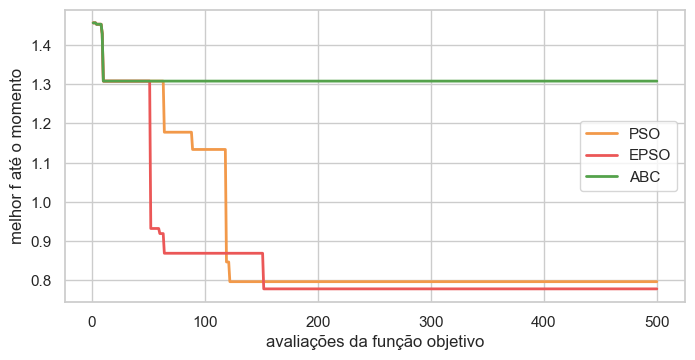

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for (nome, m), cor in zip(mols.items(), [LARANJA, "#EB5757", "#54A24B"]):
    ax.plot(range(1, len(m.convergence_) + 1), m.convergence_, label=nome.upper(), color=cor, lw=2)
ax.set_xlabel("avaliações da função objetivo")
ax.set_ylabel("melhor f até o momento")
ax.legend()
plt.show()

O PSO e o EPSO convergem para uma imagem de 2 features. O ABC não melhora em 500 avaliações: a solução
dele, de 16 features, é uma das que foram sorteadas na população inicial.

### As imagens geradas

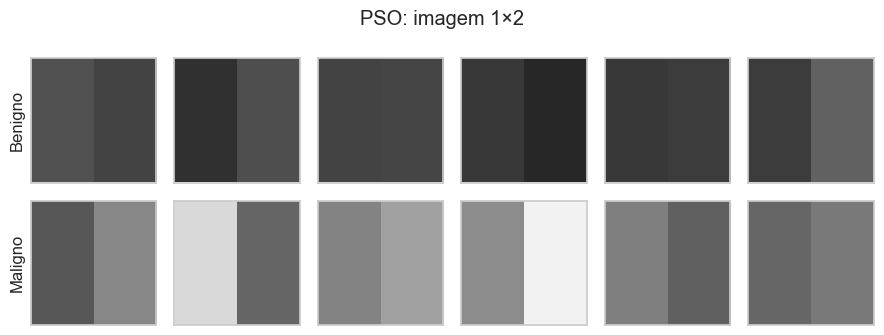

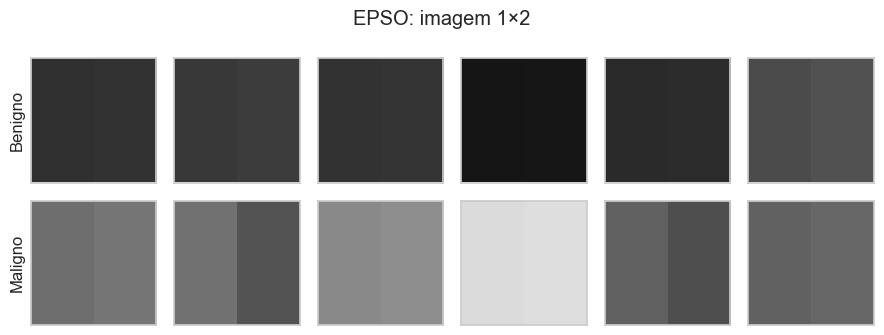

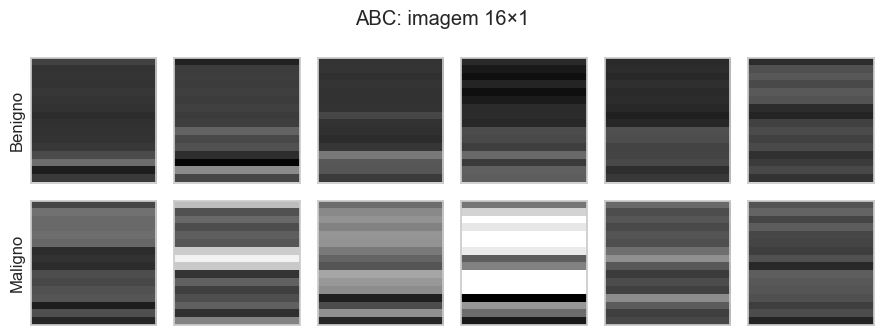

In [8]:
def mostrar_imagens(imagens, y, titulo, n=6):
    vmin, vmax = np.percentile(imagens, [1, 99])
    fig, eixos = plt.subplots(2, n, figsize=(1.5 * n, 3.4))
    for linha, (classe, nome) in enumerate([(0, "Benigno"), (1, "Maligno")]):
        for col, i in enumerate(np.where(y == classe)[0][:n]):
            ax = eixos[linha, col]
            ax.imshow(imagens[i], cmap="gray", vmin=vmin, vmax=vmax, aspect="auto")
            ax.set_xticks([])
            ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(nome)
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()

for nome, m in mols.items():
    h, w = m.image_shape_
    mostrar_imagens(m.transform(X_treino), y_treino, f"{nome.upper()}: imagem {h}×{w}")

### O que a Eq. 1 mede

Três propriedades da função objetivo aparecem ao calcular o valor dela diretamente.

In [9]:
# mesma preparação feita dentro do MOL: escala, ordem do Map e amostras ordenadas por classe
abc = mols["abc"]
Z = abc.scaler_.transform(X_treino)[:, abc.feature_order_]
Z = Z[np.argsort(y_treino, kind="stable")]

def eq1(imagens):
    # média, sobre os pares consecutivos, da diferença quadrática média entre as duas imagens
    return float(((imagens[:-1] - imagens[1:]) ** 2).mean(axis=tuple(range(1, imagens.ndim))).sum() / len(imagens))

primeiras16 = Z[:, :16]
rng = np.random.default_rng(0)
pd.Series({
    "4×4": eq1(primeiras16.reshape(-1, 4, 4)),
    "2×8": eq1(primeiras16.reshape(-1, 2, 8)),
    "16×1": eq1(primeiras16.reshape(-1, 16, 1)),
    "4×4 com os pixels embaralhados": eq1(primeiras16[:, rng.permutation(16)].reshape(-1, 4, 4)),
}, name="f (Eq. 1)").round(6).to_frame()

,f (Eq. 1)
4×4,1.12584
2×8,1.12584
16×1,1.12584
4×4 com os pixels embaralhados,1.12584


O valor é idêntico nos quatro casos. A função não depende do formato nem da posição dos pixels, então o
otimizador não tem como preferir um formato ou um arranjo.

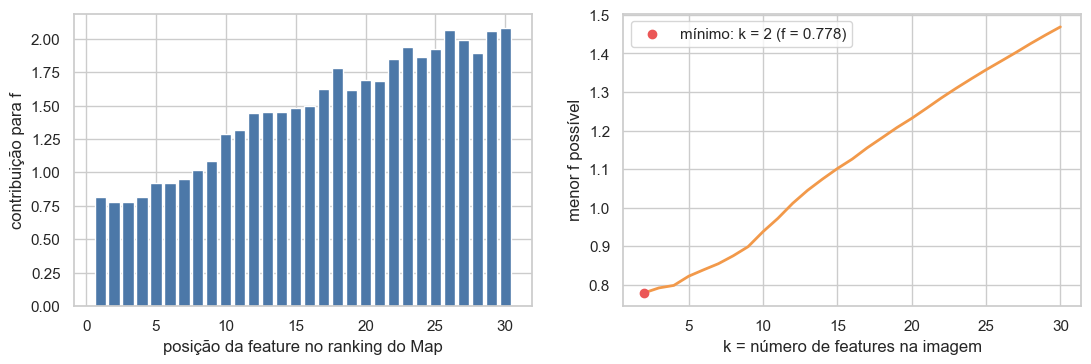

In [10]:
# contribuição de cada feature e o menor f possível com k features
D = ((Z[:-1] - Z[1:]) ** 2).sum(axis=0) / len(Z)
menor_f = [np.sort(D)[:k].mean() for k in range(2, 31)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.bar(range(1, 31), D, color="#4C78A8")
ax1.set_xlabel("posição da feature no ranking do Map")
ax1.set_ylabel("contribuição para f")
ax2.plot(range(2, 31), menor_f, color=LARANJA, lw=2)
ax2.scatter([2], [menor_f[0]], color="#EB5757", zorder=3, label=f"mínimo: k = 2 (f = {menor_f[0]:.3f})")
ax2.set_xlabel("k = número de features na imagem")
ax2.set_ylabel("menor f possível")
ax2.legend()
plt.show()

Como a função é uma média por feature, o menor valor possível acontece com 2 features. Um otimizador
eficiente chega a uma imagem 1×2, que é o que o PSO e o EPSO fazem.

## 3. Learn: a CNN

A CNN do artigo tem uma camada de convolução com 32 filtros 3×3, um max-pooling e uma camada densa.
`MOLCNNClassifier` junta as três etapas num único estimador. Abaixo, o melhor MOL do experimento
(Map euclidiano com ABC), treinado no conjunto de treino.

In [11]:
mol = MOLCNNClassifier(map_strategy="euclidean", optimizer="abc", learning_rate=1e-3, random_state=42)
mol.fit(X_treino, y_treino)
mol.model_.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 16, 1, 32)      │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │         2,313 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            10 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,931 (30.98 KB)

 Trainable params: 2,643 (10.32 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,288 (20.66 KB)

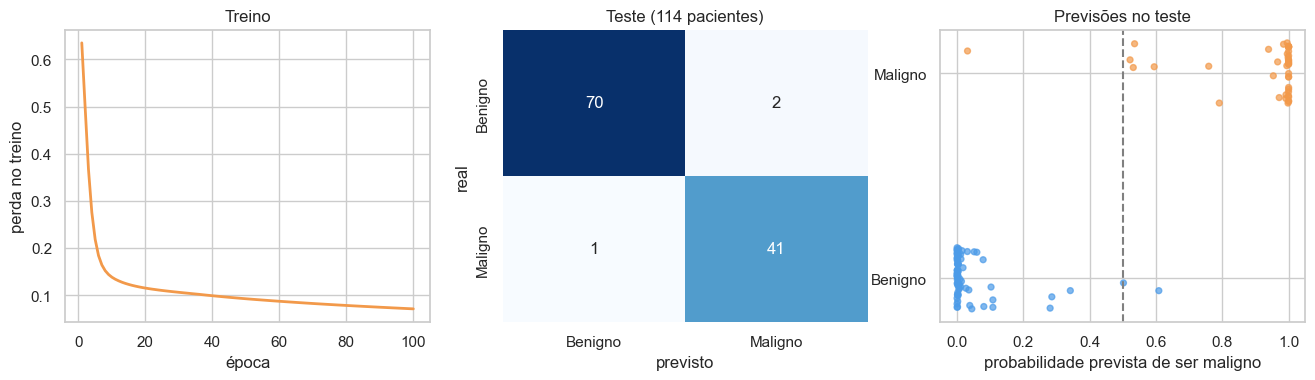

balanced_accuracy    0.974
sensitivity          0.976
specificity          0.972
roc_auc              0.994
dtype: float64

In [12]:
prob = mol.predict_proba(X_teste)[:, 1]
pred = (prob > 0.5).astype(int)
m = calculate_metrics(y_teste, pred, prob)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 3.8))
ax1.plot(range(1, 101), mol.history_["loss"], color=LARANJA, lw=2)
ax1.set_xlabel("época")
ax1.set_ylabel("perda no treino")
ax1.set_title("Treino")

sns.heatmap(confusion_matrix(y_teste, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax2,
            xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"])
ax2.set_xlabel("previsto")
ax2.set_ylabel("real")
ax2.set_title("Teste (114 pacientes)")

rng = np.random.default_rng(0)
ax3.scatter(prob, y_teste + rng.uniform(-0.15, 0.15, len(prob)), s=18, alpha=0.7,
            c=np.where(y_teste == 1, LARANJA, AZUL))
ax3.axvline(0.5, color="gray", ls="--")
ax3.set_yticks([0, 1], ["Benigno", "Maligno"])
ax3.set_xlabel("probabilidade prevista de ser maligno")
ax3.set_title("Previsões no teste")
plt.show()

pd.Series(m)[["balanced_accuracy", "sensitivity", "specificity", "roc_auc"]].round(3)

Este é um único treino, avaliado em 114 pacientes: um paciente a mais ou a menos muda a sensibilidade em
2,4 pontos percentuais. A comparação entre métodos, a seguir, usa validação cruzada.

## 4. Comparação com os métodos tradicionais

Resultados do experimento principal (`experimentos/principal.py`): 15 versões do MOL e 16 de baselines,
com grid search em 10 folds estratificados no treino.

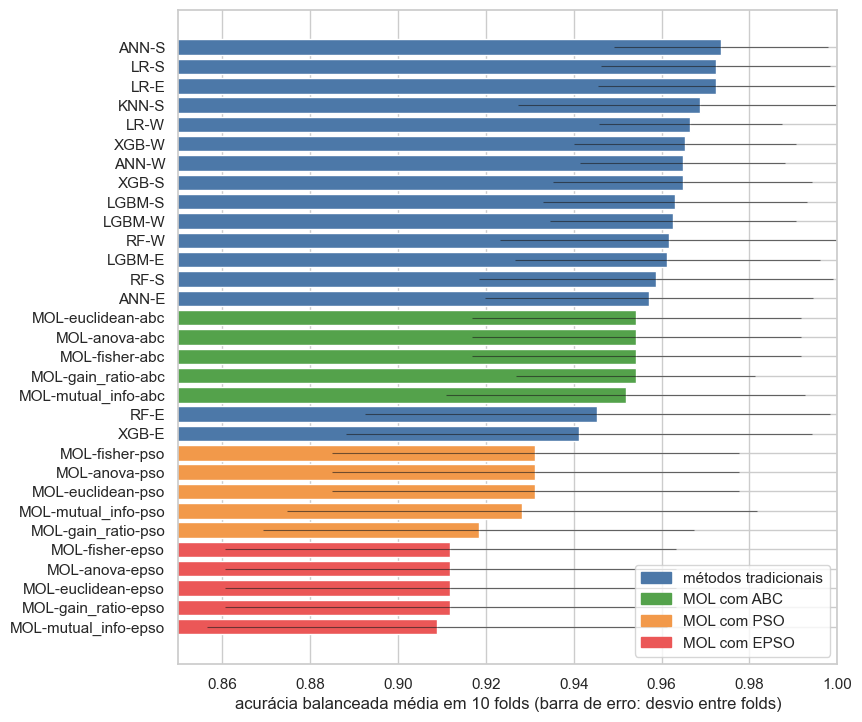

In [13]:
res = pd.read_csv(RESULTADOS / "principal" / "results.csv").sort_values("cv_balanced_accuracy_mean")
cores = np.where(res["family"] != "MOL", "#4C78A8",
                 np.where(res["optimizer"] == "abc", "#54A24B",
                          np.where(res["optimizer"] == "pso", LARANJA, "#EB5757")))

fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.barh(res["model"], res["cv_balanced_accuracy_mean"], xerr=res["cv_balanced_accuracy_std"],
        color=cores, error_kw={"lw": 0.8, "alpha": 0.6})
ax.set_xlim(0.85, 1.0)
ax.set_xlabel("acurácia balanceada média em 10 folds (barra de erro: desvio entre folds)")
legenda = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#4C78A8", "#54A24B", LARANJA, "#EB5757"]]
ax.legend(legenda, ["métodos tradicionais", "MOL com ABC", "MOL com PSO", "MOL com EPSO"], loc="lower right")
plt.show()

In [14]:
wil = pd.read_csv(RESULTADOS / "principal" / "wilcoxon.csv").set_index("compared_to")
escolhidos = ["ANN-S", "LR-S", "KNN-S", "RF-S", "XGB-S", "LGBM-S", "MOL-euclidean-pso", "MOL-euclidean-epso"]
tabela = wil.loc[escolhidos, ["diff_cv_mean", "p_value", "significant_0.05"]].round(3)
tabela.columns = ["melhor MOL − outro", "p-valor (Wilcoxon)", "significativo"]
tabela

,melhor MOL − outro,p-valor (Wilcoxon),significativo
compared_to,,,
ANN-S,-0.019,0.117,False
LR-S,-0.018,0.195,False
KNN-S,-0.015,0.094,False
RF-S,-0.004,0.672,False
XGB-S,-0.010,0.156,False
LGBM-S,-0.009,0.250,False
MOL-euclidean-pso,0.023,0.027,True
MOL-euclidean-epso,0.042,0.002,True


O melhor MOL (Map euclidiano com ABC, 0,954) fica abaixo de todos os métodos tradicionais, sem diferença
significativa. As únicas diferenças significativas estão dentro do próprio MOL: as versões com PSO e EPSO,
que otimizam melhor a Eq. 1, classificam pior.

## 5. Testes de controle

Três testes verificam se cada parte do método contribui (`experimentos/controles.py`):

1. soluções sorteadas contra as otimizadas;
2. as mesmas 16 features em formatos diferentes e com os pixels embaralhados;
3. as mesmas features numa rede comum, sem imagem.

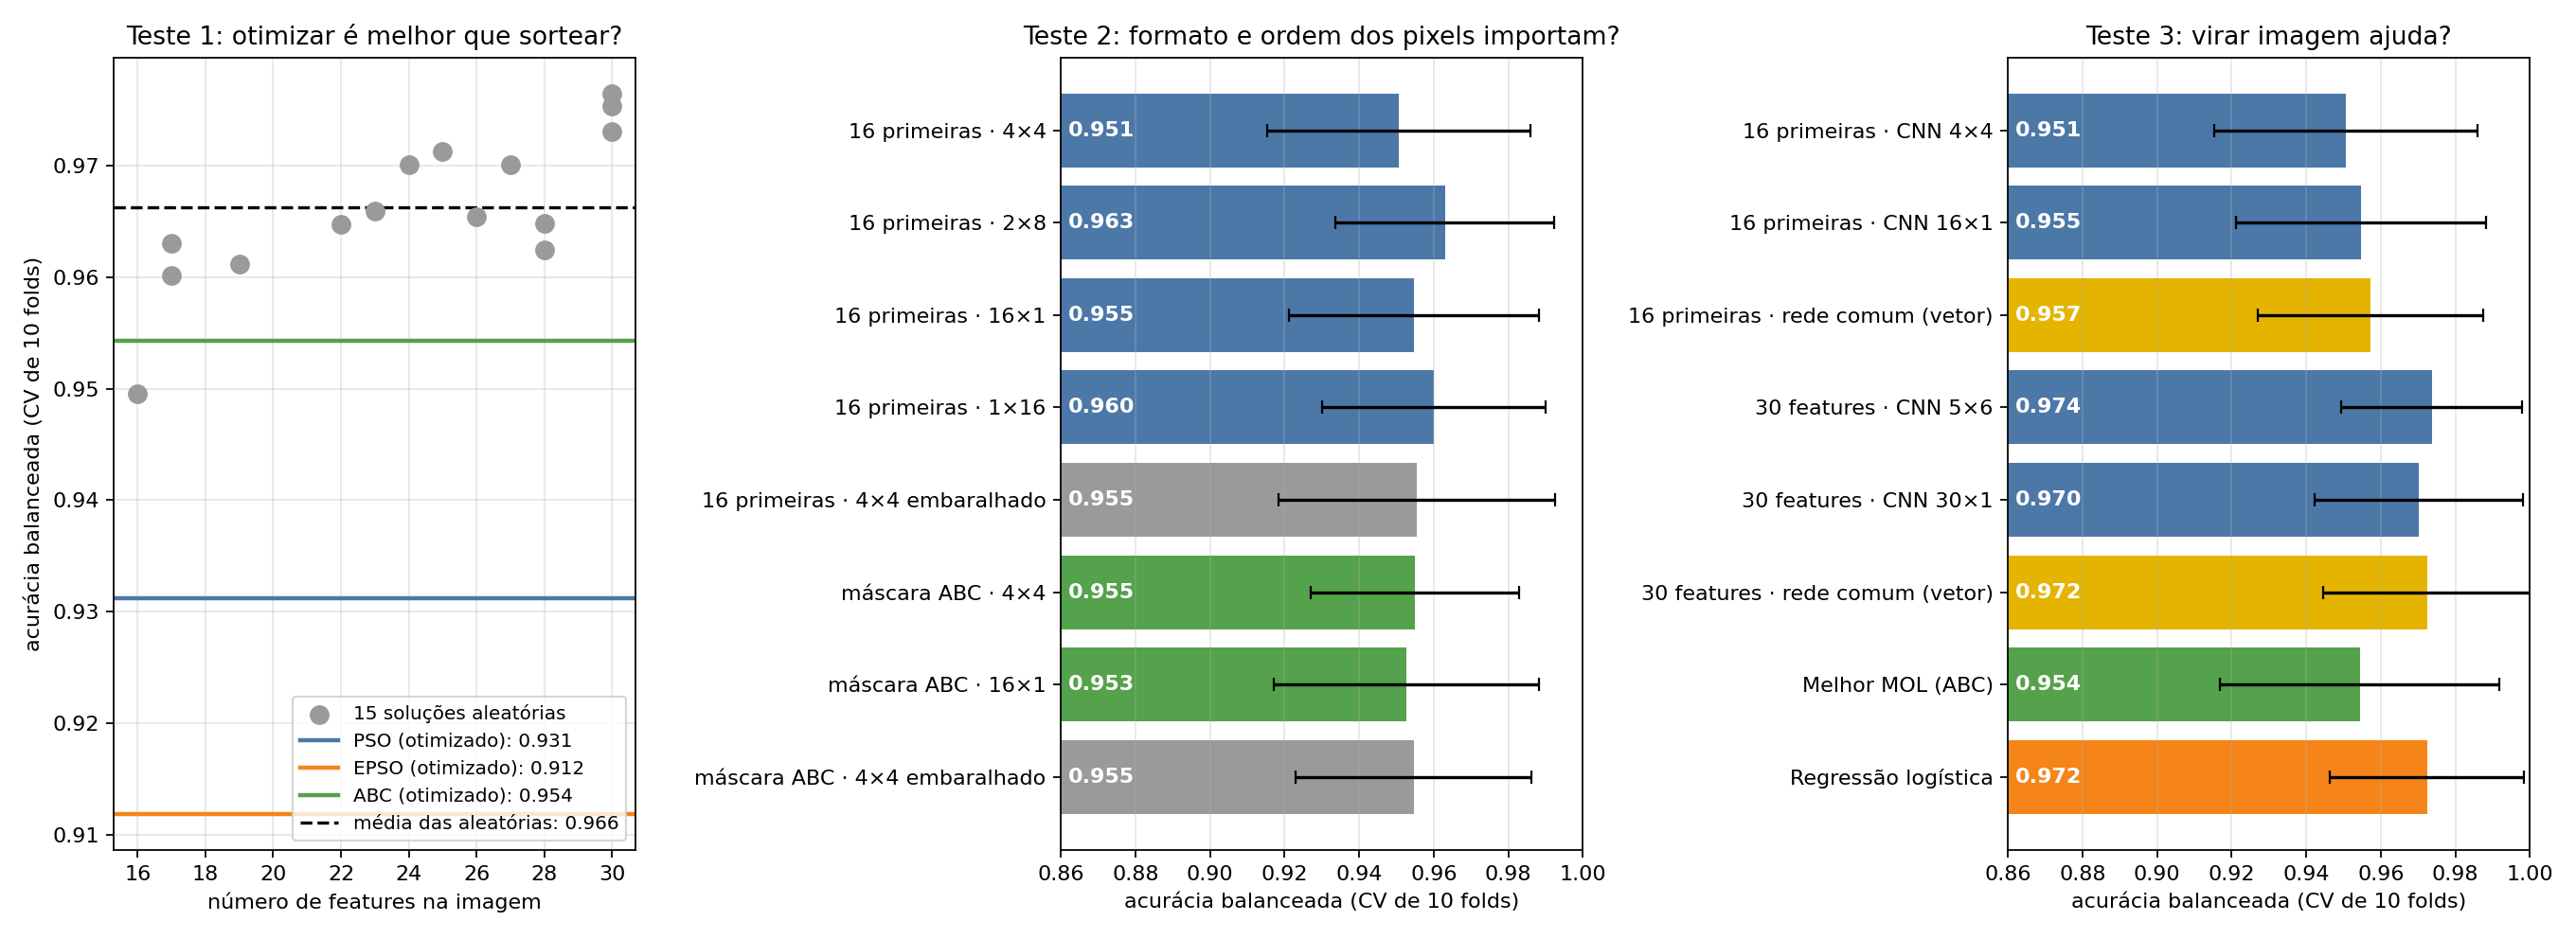

In [15]:
display(Image(filename=str(RESULTADOS / "controles" / "grafico.png")))

In [16]:
comp = pd.read_csv(RESULTADOS / "controles" / "comparacoes.csv")
comp[["teste", "pergunta", "media_A", "media_B", "p_valor"]].round(3)

,teste,pergunta,media_A,media_B,p_valor
0,1,otimizar é melhor que sortear?,0.931,0.966,0.008
1,1,otimizar é melhor que sortear?,0.912,0.966,0.004
2,1,otimizar é melhor que sortear?,0.954,0.966,0.297
3,2,o formato 2D é melhor que o vetor?,0.951,0.955,0.781
4,2,o formato quadrado é melhor que 2x8?,0.951,0.963,0.281
5,2,a ordem do Map nos pixels importa?,0.951,0.955,0.422
6,2,o formato 2D é melhor que o vetor? (máscara do...,0.955,0.953,0.812
7,2,a ordem do Map nos pixels importa? (máscara do...,0.955,0.955,0.797
8,3,a convolução ajuda? (16 primeiras),0.955,0.957,0.625
9,3,a imagem 4x4 é melhor que o vetor numa rede co...,0.951,0.957,0.500


- **Teste 1:** as soluções sorteadas superam o PSO e o EPSO, e quase todas superam o ABC. O desempenho
  acompanha o número de features, e a Eq. 1 empurra para poucas.
- **Teste 2:** nem o formato 2D nem a ordem dos pixels fazem diferença.
- **Teste 3:** a CNN na imagem empata com uma rede comum no vetor.

## 6. MOL v2: a versão corrigida

O MOL v2 troca o objetivo da otimização. Em vez da Eq. 1, ele procura o arranjo em que features
correlacionadas ocupam pixels vizinhos, que é a estrutura que uma convolução consegue aproveitar.
O formato é fixo (5×6 para 30 features) e nenhuma feature é descartada.

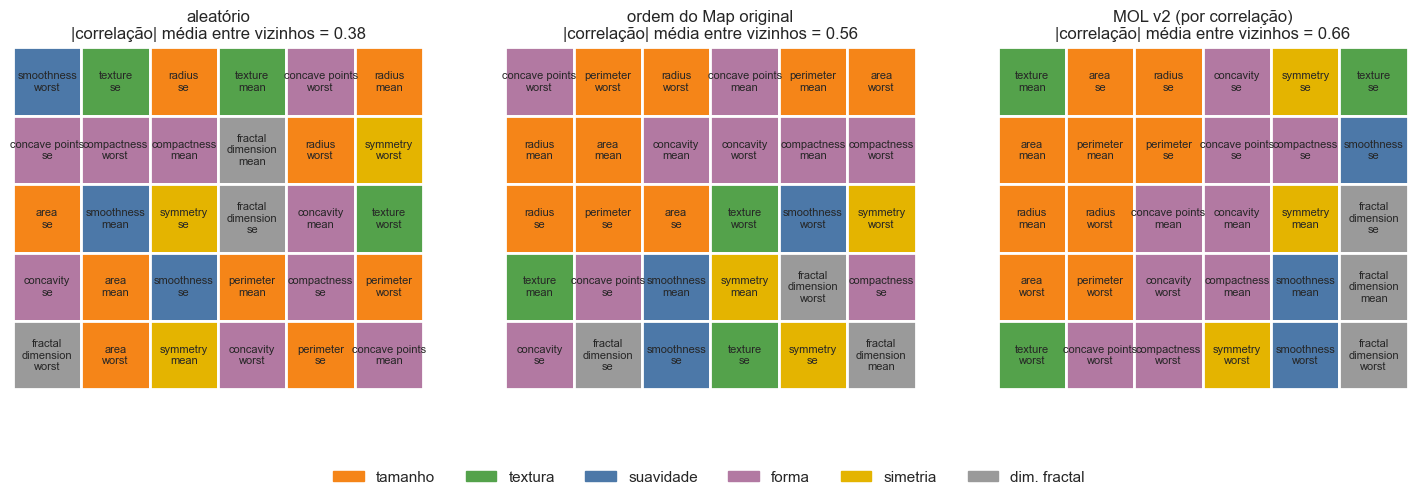

In [17]:
TIPOS = {"radius": "tamanho", "perimeter": "tamanho", "area": "tamanho", "texture": "textura",
         "smoothness": "suavidade", "compactness": "forma", "concavity": "forma", "concave points": "forma",
         "symmetry": "simetria", "fractal_dimension": "dim. fractal"}
COR_TIPO = {"tamanho": "#F58518", "textura": "#54A24B", "suavidade": "#4C78A8", "forma": "#B279A2",
            "simetria": "#E4B400", "dim. fractal": "#9A9A9A"}

arranjos = {"aleatório": MOLv2Classifier(arranjo="aleatorio", semente_arranjo=100),
            "ordem do Map original": MOLv2Classifier(arranjo="ranking"),
            "MOL v2 (por correlação)": MOLv2Classifier(arranjo="correlacao")}

fig, eixos = plt.subplots(1, 3, figsize=(18, 5.6))
for ax, (titulo, a) in zip(eixos, arranjos.items()):
    a.ajustar_arranjo(X_treino, y_treino)
    h, w = a.forma_
    for p, col in enumerate(a.colunas_):
        r, c = divmod(p, w)
        base = nomes[col].rsplit("_", 1)[0]
        ax.add_patch(plt.Rectangle((c, h - 1 - r), 1, 1, color=COR_TIPO[TIPOS[base]], ec="white", lw=2))
        ax.text(c + 0.5, h - 0.5 - r, nomes[col].replace("_", "\n"), ha="center", va="center", fontsize=8)
    ax.set_xlim(0, w)
    ax.set_ylim(0, h)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{titulo}\n|correlação| média entre vizinhos = {a.correlacao_vizinhos_:.2f}")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COR_TIPO.values()], list(COR_TIPO),
           loc="lower center", ncol=6, frameon=False)
plt.show()

No arranjo por correlação, as features de tamanho ficam juntas, assim como as de forma. A correlação média
entre pixels vizinhos quase dobra em relação ao arranjo aleatório.

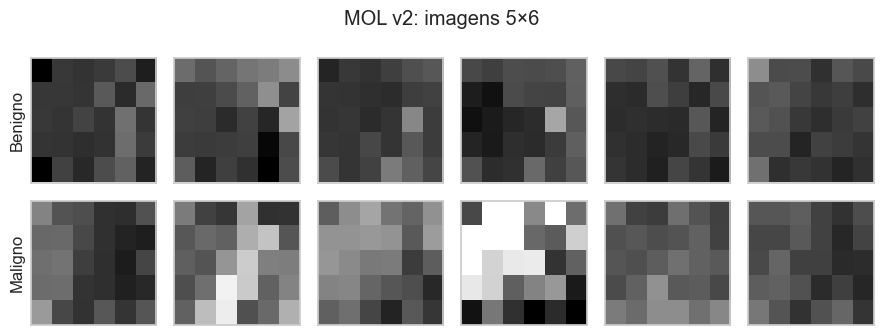

In [18]:
v2 = arranjos["MOL v2 (por correlação)"]
mostrar_imagens(v2.para_imagens(X_treino), y_treino, "MOL v2: imagens 5×6")

In [19]:
resumo = pd.read_csv(RESULTADOS / "mol_v2" / "resumo.csv")
resumo[["descricao", "cv_media", "cv_desvio_folds", "correlacao_vizinhos"]].round(3)

,descricao,cv_media,cv_desvio_folds,correlacao_vizinhos
0,"rede comum, sem imagem (30 features)",0.974,0.020,0.562
1,ANN tabular (sklearn) (experimento principal),0.974,0.024,NaN
2,Regressão logística (experimento principal),0.972,0.026,NaN
3,ordem do Map original (5×6),0.971,0.022,0.562
4,"rede comum, sem imagem (16 features mRMR)",0.971,0.027,0.669
5,pior arranjo possível (5×6),0.971,0.016,0.342
6,MOL v2 · arranjo por correlação (5×6),0.970,0.023,0.662
7,"16 features mRMR, posição aleatória (4×4)",0.969,0.025,0.527
8,pixels em posição aleatória (5×6),0.968,0.023,0.384
9,XGBoost (experimento principal),0.965,0.029,NaN


In [20]:
comp_v2 = pd.read_csv(RESULTADOS / "mol_v2" / "comparacoes.csv")
comp_v2[["pergunta", "media_A", "media_B", "diferenca", "p_valor"]].round(3)

,pergunta,media_A,media_B,diferenca,p_valor
0,arranjo otimizado é melhor que pixels aleatórios?,0.970,0.968,0.002,0.770
1,arranjo otimizado é melhor que o pior arranjo?,0.970,0.971,-0.000,0.883
2,arranjo otimizado é melhor que a ordem do Map ...,0.970,0.971,-0.001,0.734
3,a imagem é melhor que o vetor numa rede comum?,0.970,0.974,-0.004,0.156
4,MOL v2 é melhor que a regressão logística?,0.970,0.972,-0.002,0.609
5,MOL v2 é melhor que a ANN tabular?,0.970,0.974,-0.003,0.254
6,MOL v2 é melhor que o XGBoost?,0.970,0.965,0.006,0.520
7,MOL v2 é melhor que o MOL original?,0.970,0.954,0.016,0.137
8,(16 features) arranjo otimizado é melhor que a...,0.964,0.969,-0.005,0.609
9,(16 features) a imagem é melhor que o vetor?,0.964,0.971,-0.007,0.125


O MOL v2 recupera o desempenho perdido pelo MOL original (0,970 contra 0,954), mas o arranjo otimizado
empata com os pixels em posição aleatória e com o pior arranjo possível. A imagem também empata com a rede
comum e com a regressão logística. Nesta base, a estrutura espacial não traz ganho.

## 7. Usando os modelos salvos

`experimentos/salvar_modelos.py` treina e grava os modelos finais em `models/`. Abaixo, eles são carregados
e aplicados a alguns pacientes do teste.

In [21]:
MODELOS = RAIZ / "models"

map_optimize = joblib.load(MODELOS / "mol_original" / "map_optimize.joblib")
cnn = keras.models.load_model(MODELOS / "mol_original" / "cnn.keras")
p_mol = cnn.predict(map_optimize.transform(X_teste)[..., None], verbose=0)[:, 0]

arranjo = joblib.load(MODELOS / "mol_v2" / "arranjo.joblib")
cnn_v2 = keras.models.load_model(MODELOS / "mol_v2" / "cnn.keras")
z = arranjo["scaler"].transform(X_teste)[:, arranjo["colunas"]]
p_v2 = cnn_v2.predict(z.reshape(-1, *arranjo["forma"], 1), verbose=0)[:, 0]

p_lr = joblib.load(MODELOS / "lr.joblib").predict_proba(X_teste)[:, 1]

previsoes = pd.DataFrame({"diagnóstico real": np.where(y_teste == 1, "Maligno", "Benigno"),
                          "MOL original": p_mol, "MOL v2": p_v2, "regressão logística": p_lr})
previsoes.head(8).round(3)

,diagnóstico real,MOL original,MOL v2,regressão logística
0,Benigno,0.001,0.000,0.000
1,Maligno,1.000,1.000,1.000
2,Benigno,0.081,0.000,0.043
3,Maligno,0.791,1.000,0.580
4,Benigno,0.012,0.022,0.511
5,Benigno,0.000,0.000,0.001
6,Maligno,0.595,0.992,0.763
7,Benigno,0.003,0.000,0.001


In [22]:
pd.DataFrame({nome: calculate_metrics(y_teste, (p > 0.5).astype(int), p)
              for nome, p in [("MOL original", p_mol), ("MOL v2", p_v2), ("regressão logística", p_lr)]}) \
    .loc[["balanced_accuracy", "sensitivity", "specificity", "roc_auc"]].round(3)

,MOL original,MOL v2,regressão logística
balanced_accuracy,0.974,0.969,0.969
sensitivity,0.976,0.952,0.952
specificity,0.972,0.986,0.986
roc_auc,0.994,0.995,0.996


In [23]:
discordam = previsoes[((previsoes[["MOL original", "MOL v2", "regressão logística"]] > 0.5).nunique(axis=1) > 1)]
print(f"Pacientes do teste em que os três modelos não concordam: {len(discordam)} de {len(previsoes)}")
discordam.round(3)

Pacientes do teste em que os três modelos não concordam: 6 de 114


,diagnóstico real,MOL original,MOL v2,regressão logística
4,Benigno,0.012,0.022,0.511
56,Benigno,0.013,0.896,0.052
64,Benigno,0.609,0.143,0.015
75,Benigno,0.502,0.000,0.035
87,Maligno,1.000,1.000,0.321
112,Maligno,0.522,0.200,0.504


## Conclusões

- O MOL foi implementado a partir do artigo e aplicado com o protocolo dele. Nesta base, a melhor versão
  fica abaixo dos métodos tradicionais, sem diferença estatisticamente significativa.
- A função objetivo da etapa Optimize não depende do formato da imagem nem da posição dos pixels, e seu
  mínimo é uma imagem de 2 features. Por isso otimizar melhor leva a classificar pior.
- Os testes de controle mostram que sortear a solução, embaralhar os pixels ou dispensar a imagem não
  pioram o resultado.
- O MOL v2 corrige a função objetivo e recupera o desempenho, mas não supera uma rede comum nem uma
  regressão logística.

Estes resultados valem para uma base pequena, com 30 features, em que um modelo linear já chega a 0,97.
Eles não dizem como a abordagem se comporta com centenas ou milhares de features correlacionadas.